# NB09 — Streaming Entropy-Trajectory Detector

**Goal (HANDOFF §13, item 8):** Test whether sliding-window streaming inference catches Conti_06's moderate→high entropy transition, lifting detection above the static 20% recall.

**Key insight from NB08:** Conti_06 is NOT write-silent — it writes in all 300 windows at *moderate entropy* early (init/scan phase), transitioning to *very-high entropy* at encryption onset. The static one-shot 30 s verdict sees the majority of moderate-entropy windows and calls it benign. Streaming can detect the *transition* the moment it happens.

**Approach:**
- Reuse `classifier.pt` (CNN1D with global-mean-pool is sequence-length agnostic)
- Slide a W=50 window (5 s context) with stride=5 across each execution's 300 windows
- Record Ransomware probability at each position
- Detection = first position where P(Ransomware) ≥ 0.70
- Compare streaming recall vs static 20% baseline for Conti_06; check FPR on Benign/Legit-Enc


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import json as _json
import warnings
from pathlib import Path
from collections import defaultdict
warnings.filterwarnings('ignore')

# ── Config ─────────────────────────────────────────────────────────────────────
FEATURES_DIR   = Path('features')
W              = 50          # context window: 50 × 0.1 s = 5 s
STRIDE         = 5           # slide stride in time-windows (0.5 s per step)
THRESHOLD      = 0.70        # ransomware-confidence trigger
T_WINDOW       = 0.1         # seconds per time-window
N_WINDOWS      = 300         # windows per execution
RANSOMWARE_IDX = 2           # CLASS_ORDER = ['Benign','Legit-Enc','Ransomware'] → idx 2
DEVICE         = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEED           = 42

LABEL_3WAY = {
    'WannaCry':'Ransomware', 'Ryuk':'Ransomware', 'REvil':'Ransomware',
    'LockBit':'Ransomware',  'Darkside':'Ransomware', 'Conti':'Ransomware',
    'AESCrypt':'Legit-Encryption', 'SDelete':'Legit-Encryption', 'Zip':'Legit-Encryption',
    'Firefox':'Benign', 'Office':'Benign', 'Idle':'Benign',
}
STATIC_BASELINE = {  # from NB07b single-pass results
    'Conti_01': 1.0, 'Conti_02': 1.0, 'Conti_03': 1.0, 'Conti_04': 1.0,
    'Conti_05': 1.0, 'Conti_06': 0.2, 'Conti_07': 1.0,
}
VARIANT_CLASSES = [f'Conti_0{i}' for i in range(1, 8)]

n_positions = (N_WINDOWS - W) // STRIDE + 1
print(f"Device      : {DEVICE}")
print(f"Context W   : {W} windows = {W*T_WINDOW:.1f} s")
print(f"Stride      : {STRIDE} windows = {STRIDE*T_WINDOW:.2f} s per step")
print(f"Positions   : {n_positions} per execution")
print(f"Threshold   : {THRESHOLD}  (Ransomware idx={RANSOMWARE_IDX})")


Device      : cpu
Context W   : 50 windows = 5.0 s
Stride      : 5 windows = 0.50 s per step
Positions   : 51 per execution
Threshold   : 0.7  (Ransomware idx=2)


In [2]:
X        = np.load(FEATURES_DIR / 'text_sequences.npy')           # (190, 300, 384)
meta     = pd.read_csv(FEATURES_DIR / 'metadata.csv')
split    = np.load(FEATURES_DIR / 'fewshot_split_cnn.npz', allow_pickle=True)

train_idx   = split['train_idx']      # 96 originals (train)
val_idx     = split['val_idx']        # 24 originals (val)
test_idx    = split['test_idx']       # 70 Conti variants
labels_3way = split['labels_3way']    # 190 entries: 'Ransomware'/'Legit-Encryption'/'Benign'/'Conti_0x'
labels_fine = split['labels_fine']    # 190 fine-grained family labels

exec_dirs = meta['exec_dir'].values   # raw execution directories

print(f"Embeddings  : {X.shape}")
print(f"Split       : train={len(train_idx)}, val={len(val_idx)}, test(variants)={len(test_idx)}")
print(f"Val classes : {dict(pd.Series(labels_3way[val_idx]).value_counts())}")
print(f"Variants    : {dict(pd.Series(labels_3way[test_idx]).value_counts())}")


Embeddings  : (190, 300, 384)
Split       : train=96, val=24, test(variants)=70
Val classes : {'Ransomware': np.int64(12), 'Legit-Encryption': np.int64(6), 'Benign': np.int64(6)}
Variants    : {'Conti_01': np.int64(10), 'Conti_02': np.int64(10), 'Conti_03': np.int64(10), 'Conti_04': np.int64(10), 'Conti_05': np.int64(10), 'Conti_06': np.int64(10), 'Conti_07': np.int64(10)}


In [3]:
class TextEmbeddingClassifier(nn.Module):
    """Exact architecture from NB07b — must match classifier.pt state dict.
    Global-mean-pool (features.mean(dim=-1)) is sequence-length agnostic:
    same weights work for any W without retraining.
    forward() returns (logits, recon, pooled).
    """
    def __init__(self, seq_len=300, emb_dim=384, n_classes=3):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(emb_dim, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128), nn.ReLU(),
            nn.Conv1d(128, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),  nn.ReLU(),
        )
        self.classifier = nn.Sequential(
            nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(32, n_classes),
        )
        self.reconstructor = nn.Sequential(
            nn.Linear(64, 128), nn.ReLU(),
            nn.Linear(128, emb_dim),
        )

    def forward(self, x):
        x_t      = x.permute(0, 2, 1)       # (B, emb_dim, W)
        features = self.conv(x_t)            # (B, 64, W)
        pooled   = features.mean(dim=-1)     # (B, 64) — global mean pool
        logits   = self.classifier(pooled)   # (B, 3)
        recon    = self.reconstructor(pooled)
        return logits, recon, pooled

model = TextEmbeddingClassifier().to(DEVICE)
model.load_state_dict(torch.load(FEATURES_DIR / 'classifier.pt',
                                  map_location=DEVICE, weights_only=False))
model.eval()
print("Loaded classifier.pt  (TextEmbeddingClassifier, NB07b architecture)")
print("Conv: 384->128->64 w/ BN+ReLU | Classifier: 64->32->3 | GlobalMeanPool")
print("Sequence-length agnostic — same weights run on any W without retraining.")


Loaded classifier.pt  (TextEmbeddingClassifier, NB07b architecture)
Conv: 384->128->64 w/ BN+ReLU | Classifier: 64->32->3 | GlobalMeanPool
Sequence-length agnostic — same weights run on any W without retraining.


In [4]:
def get_entropy_profile(exec_dir, n_windows=N_WINDOWS, t_window=T_WINDOW):
    """Mean ata_write Shannon entropy per 0.1 s time-window.
    ata_write.csv: no header, cols = ts, tns, LBA, size, entropy, flag
    Returns (n_windows,) float32 — zeros where no events.
    """
    profile = np.zeros(n_windows, dtype=np.float32)
    try:
        df = pd.read_csv(
            Path(exec_dir) / 'ata_write.csv',
            header=None,
            names=['ts', 'tns', 'LBA', 'size', 'entropy', 'flag'],
            usecols=['tns', 'entropy'],
        )
        if len(df) == 0:
            return profile
        df = df.sort_values('tns')
        ref_ns  = int(df['tns'].iloc[0])
        t_delta = (df['tns'] - ref_ns).values
        win_idx = (t_delta / (t_window * 1e9)).astype(int).clip(0, n_windows - 1)
        df = df.copy()
        df['win'] = win_idx
        per_win = df.groupby('win')['entropy'].mean()
        for w, e in per_win.items():
            profile[int(w)] = float(e)
    except Exception:
        pass
    return profile

print("Extracting per-window write-entropy profiles from raw ata_write.csv files …")
entropy_profiles = np.zeros((len(meta), N_WINDOWS), dtype=np.float32)
for i, row in meta.iterrows():
    entropy_profiles[i] = get_entropy_profile(row['exec_dir'])

active = (entropy_profiles.max(axis=1) > 0).sum()
print(f"  Profiles with ≥1 event : {active}/{len(meta)}")

# Quick sanity on Conti_06
c06_mask = np.array([l == 'Conti_06' for l in labels_fine])
c06_idx  = np.where(c06_mask)[0]
print(f"\nConti_06 mean entropy per execution:")
for i in c06_idx:
    ent = entropy_profiles[i]
    nz  = ent[ent > 0]
    print(f"  exec {i}: mean={nz.mean():.3f}, max={nz.max():.3f}, "
          f"windows_with_events={len(nz)}/300")


Extracting per-window write-entropy profiles from raw ata_write.csv files …
  Profiles with ≥1 event : 190/190

Conti_06 mean entropy per execution:
  exec 170: mean=0.402, max=0.540, windows_with_events=10/300
  exec 171: mean=0.393, max=0.519, windows_with_events=10/300
  exec 172: mean=0.402, max=0.581, windows_with_events=10/300
  exec 173: mean=0.386, max=0.494, windows_with_events=10/300
  exec 174: mean=0.381, max=0.502, windows_with_events=10/300
  exec 175: mean=0.409, max=0.477, windows_with_events=10/300
  exec 176: mean=0.390, max=0.501, windows_with_events=10/300
  exec 177: mean=0.393, max=0.504, windows_with_events=10/300
  exec 178: mean=0.382, max=0.482, windows_with_events=10/300
  exec 179: mean=0.379, max=0.491, windows_with_events=10/300


In [5]:
@torch.no_grad()
def stream_exec(embedding, W=W, stride=STRIDE):
    """Slide context window across one execution.
    embedding : (300, 384) ndarray
    Returns:
        positions  : (n_pos,) start-window indices
        ran_probs  : (n_pos,) P(Ransomware)
    """
    positions, ran_probs = [], []
    for start in range(0, N_WINDOWS - W + 1, stride):
        x      = torch.FloatTensor(embedding[start:start+W]).unsqueeze(0).to(DEVICE)
        logits, _, _ = model(x)
        prob   = torch.softmax(logits, dim=1).cpu().numpy()[0, RANSOMWARE_IDX]
        positions.append(start)
        ran_probs.append(float(prob))
    return np.array(positions), np.array(ran_probs)

def time_to_detect(positions, ran_probs, threshold=THRESHOLD, W=W, t_window=T_WINDOW):
    """First detection time (seconds from execution start), or None.
    Detection fires at the END of the first triggering sub-window.
    """
    hits = np.where(ran_probs >= threshold)[0]
    if len(hits):
        end_window = positions[hits[0]] + W   # last window in the triggering sub-seq
        return end_window * t_window          # seconds
    return None

# Smoke test
_idx = c06_idx[0]
_pos, _probs = stream_exec(X[_idx])
_ttd = time_to_detect(_pos, _probs)
print(f"Conti_06 smoke (exec {_idx}): max_prob={_probs.max():.3f}, "
      f"detected={_ttd is not None}"
      + (f", TTD={_ttd:.1f} s" if _ttd else ""))
print(f"  → probability curve (every 5th): {_probs[::5].round(3).tolist()}")


Conti_06 smoke (exec 170): max_prob=0.996, detected=True, TTD=6.0 s
  → probability curve (every 5th): [0.204, 0.969, 0.994, 0.428, 0.013, 0.057, 0.001, 0.022, 0.017, 0.001, 0.001]


In [6]:
eval_idx = np.concatenate([test_idx, val_idx])
records  = []

for i in eval_idx:
    pos, ran_probs = stream_exec(X[i])
    ttd = time_to_detect(pos, ran_probs)
    records.append({
        'exec_idx'  : int(i),
        'label_3way': str(labels_3way[i]),
        'label_fine': str(labels_fine[i]),
        'detected'  : ttd is not None,
        'ttd_s'     : float(ttd) if ttd is not None else None,
        'max_prob'  : float(ran_probs.max()),
        'mean_prob' : float(ran_probs.mean()),
        'positions' : pos.tolist(),
        'ran_probs' : ran_probs.tolist(),
    })

df = pd.DataFrame(records)
print(f"Streaming inference complete  ({len(eval_idx)} executions, "
      f"{n_positions} positions each).")


Streaming inference complete  (94 executions, 51 positions each).


In [7]:
var_df = df[df['label_3way'].isin(VARIANT_CLASSES)]

print(f"\n{'─'*58}")
print(f"{'Variant':<12} {'Streaming':>14} {'Mean TTD':>10} {'Static':>10}")
print(f"{'─'*58}")
for vname in VARIANT_CLASSES:
    sub    = var_df[var_df['label_3way'] == vname]
    n      = len(sub)
    det    = int(sub['detected'].sum())
    ttds   = sub.loc[sub['detected'], 'ttd_s'].dropna()
    recall = f'{det}/{n} ({100*det/n:.0f}%)'
    ttd_s  = f'{ttds.mean():.1f} s' if len(ttds) else '—'
    static = f"{int(STATIC_BASELINE.get(vname,0)*100)}%"
    marker = ' ◀' if vname == 'Conti_06' else ''
    print(f"{vname+marker:<14} {recall:>12} {ttd_s:>10} {static:>10}")
print(f'─'*58)

all_var   = var_df
all_det   = int(all_var['detected'].sum())
all_n     = len(all_var)
print(f"{'ALL variants':<14} {all_det}/{all_n} ({100*all_det/all_n:.0f}%)")



──────────────────────────────────────────────────────────
Variant           Streaming   Mean TTD     Static
──────────────────────────────────────────────────────────
Conti_01       10/10 (100%)      6.8 s       100%
Conti_02       10/10 (100%)     10.4 s       100%
Conti_03       10/10 (100%)     10.2 s       100%
Conti_04       10/10 (100%)      9.1 s       100%
Conti_05       10/10 (100%)      9.4 s       100%
Conti_06 ◀       8/10 (80%)      7.2 s        20%
Conti_07       10/10 (100%)     10.2 s       100%
──────────────────────────────────────────────────────────
ALL variants   68/70 (97%)


In [8]:
val_df = df[df['exec_idx'].isin(val_idx)]

print(f"\n── False-positive check on val set (threshold={THRESHOLD}) ──")
print(f"{'Class':<22} {'Triggered':>10} {'FPR':>8}")
print('─' * 44)
for cls in ['Benign', 'Legit-Encryption', 'Ransomware']:
    sub = val_df[val_df['label_3way'] == cls]
    if len(sub) == 0:
        continue
    fp  = int(sub['detected'].sum())
    n   = len(sub)
    fpr = fp / n
    print(f'{cls:<22} {fp}/{n:>5}      {fpr*100:>5.0f}%')
print()
print('Legit-Encryption = AESCrypt + SDelete + Zip — the critical false-positive risk.')



── False-positive check on val set (threshold=0.7) ──
Class                   Triggered      FPR
────────────────────────────────────────────
Benign                 2/    6         33%
Legit-Encryption       5/    6         83%
Ransomware             12/   12        100%

Legit-Encryption = AESCrypt + SDelete + Zip — the critical false-positive risk.


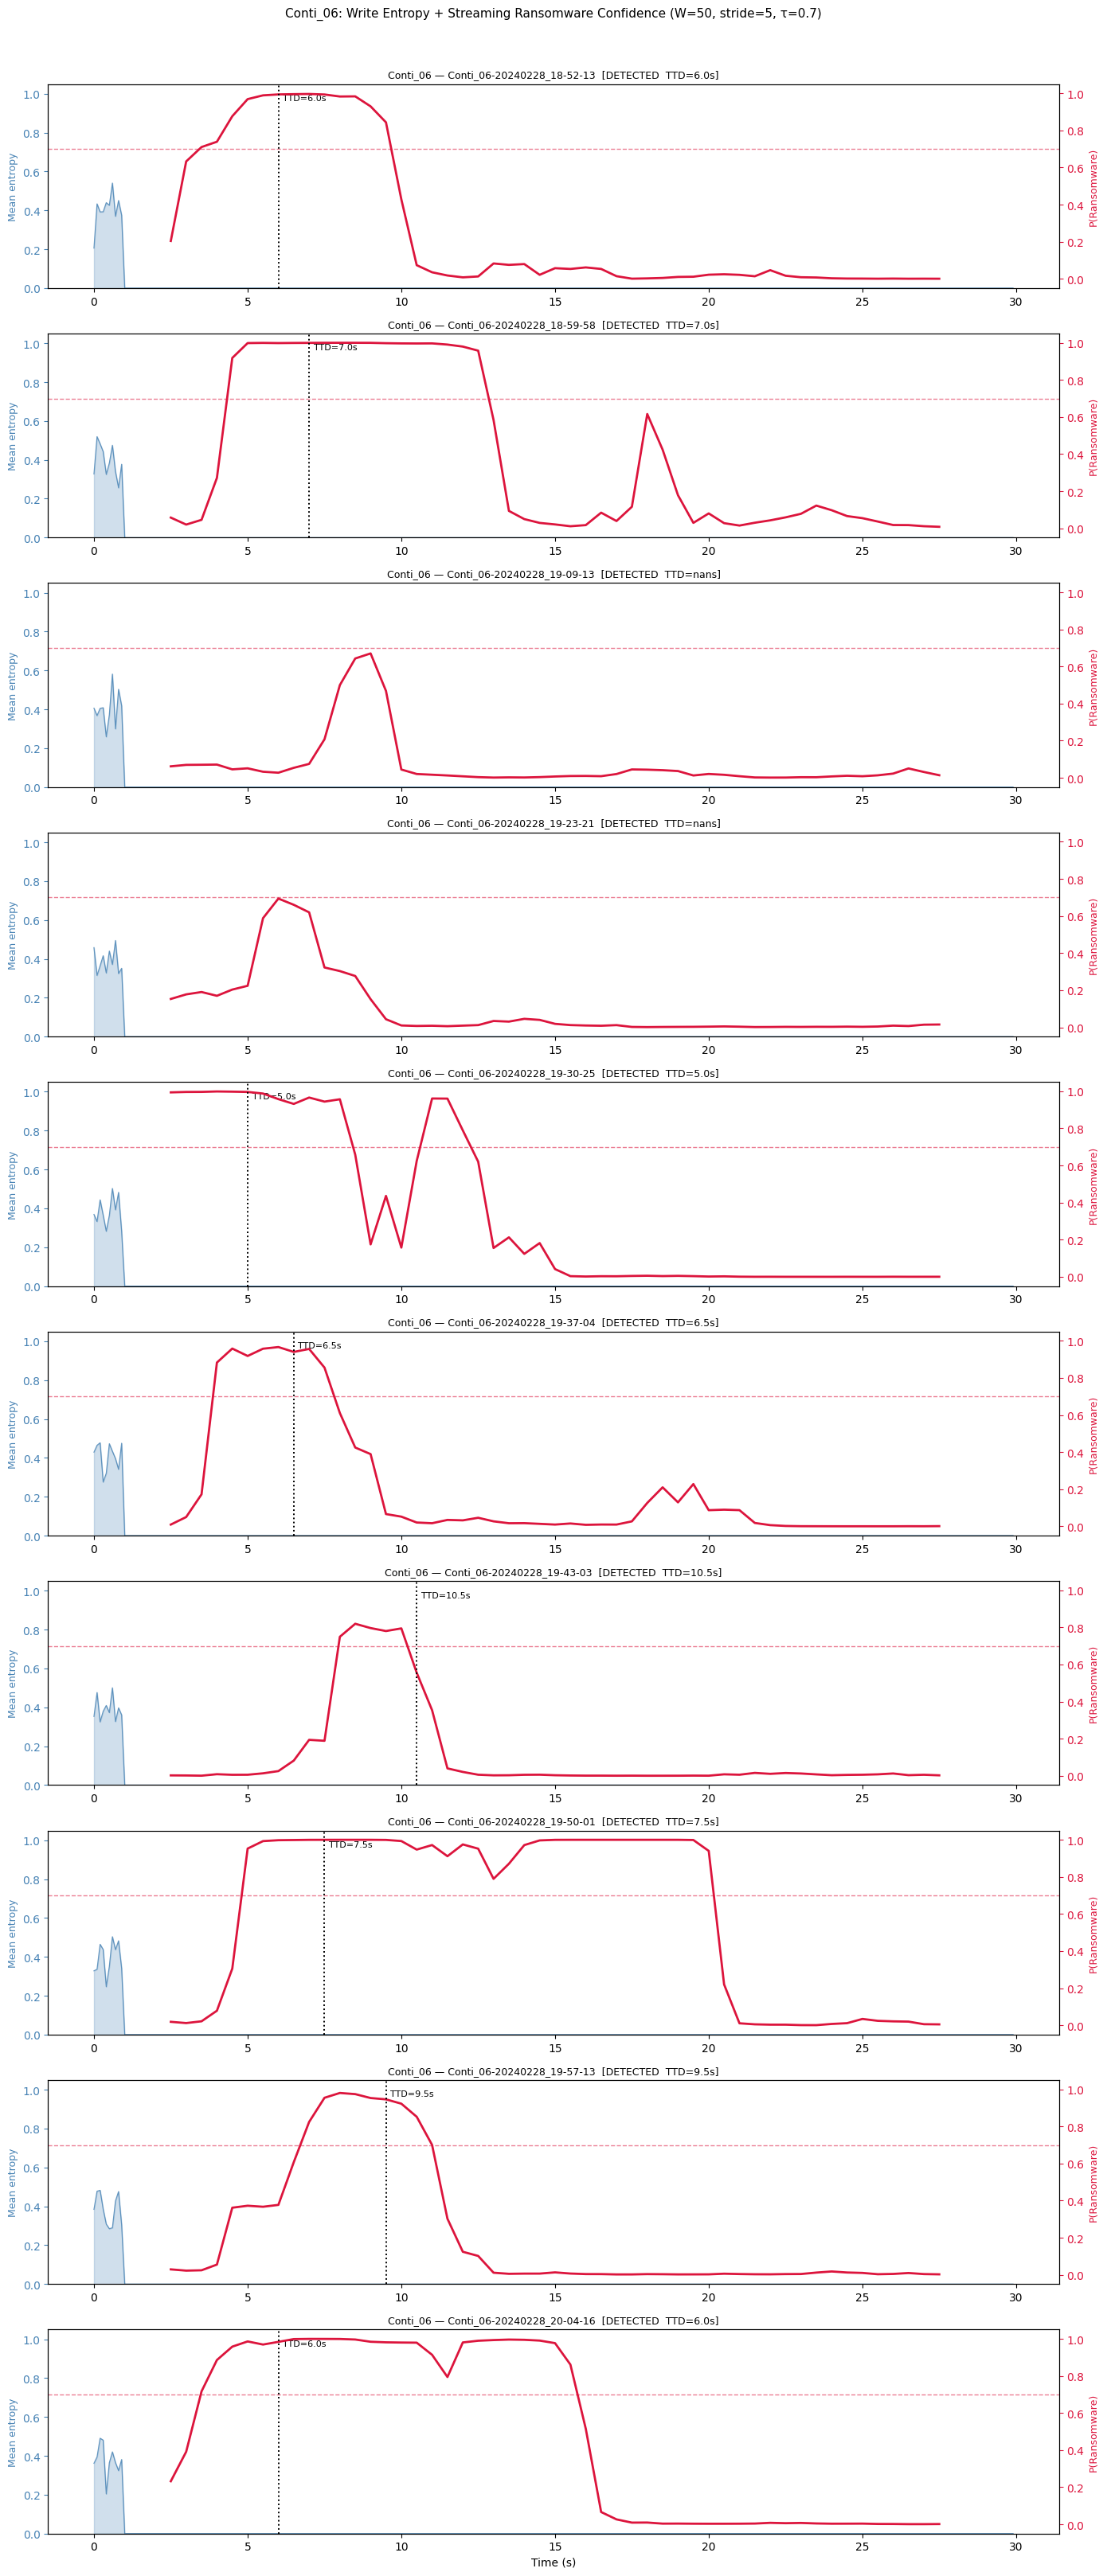

Saved → conti06_streaming_trajectory.png


In [9]:
c06_records = df[df['label_fine'] == 'Conti_06'].sort_values('exec_idx')
n_plot = len(c06_records)

fig, axes = plt.subplots(n_plot, 1, figsize=(14, 3.2 * n_plot), squeeze=False)

time_full = np.arange(N_WINDOWS) * T_WINDOW   # 0 .. 29.9 s

for ax_row, (_, row) in zip(axes, c06_records.iterrows()):
    ax  = ax_row[0]
    ax2 = ax.twinx()

    idx  = int(row['exec_idx'])
    ent  = entropy_profiles[idx]
    pos  = np.array(row['positions'])
    prob = np.array(row['ran_probs'])
    # Centre each sub-window in time
    pos_t = (pos + W / 2) * T_WINDOW

    # Entropy (background fill)
    ax.fill_between(time_full, ent, alpha=0.25, color='steelblue')
    ax.plot(time_full, ent, color='steelblue', lw=0.9, alpha=0.8, label='Write entropy')
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Mean entropy', color='steelblue', fontsize=9)
    ax.tick_params(axis='y', colors='steelblue')

    # Confidence curve
    ax2.plot(pos_t, prob, color='crimson', lw=2.0, label='P(Ransomware)')
    ax2.axhline(THRESHOLD, color='crimson', ls='--', lw=1.0, alpha=0.55,
                label=f'Threshold {THRESHOLD}')
    ax2.set_ylim(-0.05, 1.05)
    ax2.set_ylabel('P(Ransomware)', color='crimson', fontsize=9)
    ax2.tick_params(axis='y', colors='crimson')

    # TTD marker
    ttd = row['ttd_s']
    if ttd is not None:
        ax2.axvline(ttd, color='black', ls=':', lw=1.4)
        ax.annotate(f'TTD={ttd:.1f}s', xy=(ttd, 0.92),
                    xycoords=('data', 'axes fraction'),
                    fontsize=8, color='black',
                    xytext=(4, 0), textcoords='offset points')

    exec_name = Path(meta.iloc[idx]['exec_dir']).name
    detected_str = f'DETECTED  TTD={ttd:.1f}s' if (ttd is not None and ttd == ttd) else 'NOT DETECTED'
    ax.set_title(f'Conti_06 — {exec_name}  [{detected_str}]', fontsize=9)

axes[-1][0].set_xlabel('Time (s)', fontsize=10)
fig.suptitle(
    f'Conti_06: Write Entropy + Streaming Ransomware Confidence (W={W}, stride={STRIDE}, τ={THRESHOLD})',
    fontsize=11, y=1.01
)
plt.tight_layout()
plot_path = 'conti06_streaming_trajectory.png'
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {plot_path}")


── Val set max P(Ransomware) distribution ──
  Benign                mean=0.456  min=0.033  max=0.998    n=6
  Legit-Encryption      mean=0.913  min=0.541  max=0.999    n=6
  Ransomware            mean=0.998  min=0.983  max=1.000    n=12



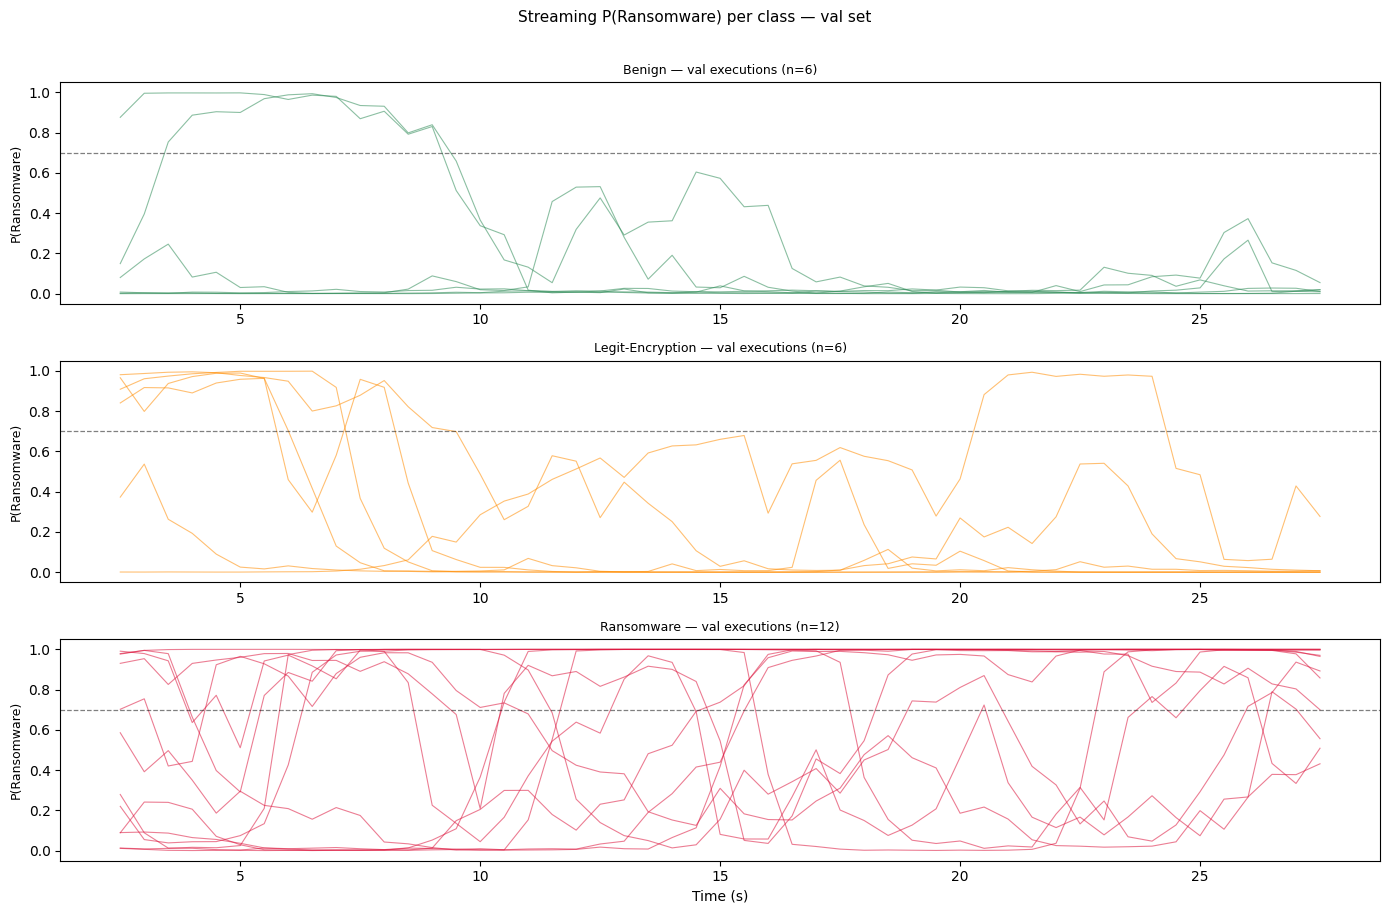

Saved → streaming_val_curves.png


In [10]:
# Sanity check: streaming confidence on known ransomware + legit-enc in val
print("── Val set max P(Ransomware) distribution ──")
for cls in ['Benign', 'Legit-Encryption', 'Ransomware']:
    sub = val_df[val_df['label_3way'] == cls]
    if len(sub):
        mp = sub['max_prob'].values
        print(f'  {cls:<20}  mean={mp.mean():.3f}  min={mp.min():.3f}  max={mp.max():.3f}  '
              f'  n={len(sub)}')

print()
# Plot confidence curves for all val classes (one row each)
val_classes = ['Benign', 'Legit-Encryption', 'Ransomware']
fig, axes = plt.subplots(len(val_classes), 1, figsize=(14, 3 * len(val_classes)), squeeze=False)
COLORS = {'Benign': 'seagreen', 'Legit-Encryption': 'darkorange', 'Ransomware': 'crimson'}

for ax_row, cls in zip(axes, val_classes):
    ax  = ax_row[0]
    sub = val_df[val_df['label_3way'] == cls]
    for _, row in sub.iterrows():
        pos  = np.array(row['positions'])
        prob = np.array(row['ran_probs'])
        pos_t = (pos + W / 2) * T_WINDOW
        ax.plot(pos_t, prob, color=COLORS[cls], lw=0.8, alpha=0.55)
    ax.axhline(THRESHOLD, color='black', ls='--', lw=0.9, alpha=0.5)
    ax.set_ylim(-0.05, 1.05)
    ax.set_ylabel('P(Ransomware)', fontsize=9)
    ax.set_title(f'{cls} — val executions (n={len(sub)})', fontsize=9)

axes[-1][0].set_xlabel('Time (s)')
fig.suptitle('Streaming P(Ransomware) per class — val set', fontsize=11, y=1.01)
plt.tight_layout()
plt.savefig('streaming_val_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved → streaming_val_curves.png")


In [11]:
class NpEncoder(_json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.integer): return int(obj)
        if isinstance(obj, np.floating): return float(obj)
        if isinstance(obj, np.bool_): return bool(obj)
        if isinstance(obj, np.ndarray): return obj.tolist()
        return super().default(obj)

streaming_summary = {}
for vname in VARIANT_CLASSES:
    sub  = df[df['label_3way'] == vname]
    n    = len(sub)
    det  = int(sub['detected'].sum())
    ttds = sub.loc[sub['detected'], 'ttd_s'].dropna().tolist()
    streaming_summary[vname] = {
        'n': n, 'detected': det,
        'recall': round(det / n, 4) if n else 0,
        'mean_ttd_s': round(float(np.mean(ttds)), 2) if ttds else None,
        'static_recall': STATIC_BASELINE.get(vname),
    }

fpr_summary = {}
for cls in ['Benign', 'Legit-Encryption', 'Ransomware']:
    sub = val_df[val_df['label_3way'] == cls]
    if len(sub):
        fp = int(sub['detected'].sum())
        fpr_summary[cls] = {'n': len(sub), 'triggered': fp,
                            'fpr': round(fp / len(sub), 4)}

out = {
    'config': {
        'W': W, 'stride': STRIDE, 'threshold': THRESHOLD,
        'n_positions': n_positions, 'ransomware_idx': RANSOMWARE_IDX,
    },
    'streaming_variant_recall': streaming_summary,
    'val_fpr': fpr_summary,
}

out_path = FEATURES_DIR / 'streaming_results.json'
with open(out_path, 'w') as f:
    _json.dump(out, f, cls=NpEncoder, indent=2)
print(f"Results saved → {out_path}")

print(f"\n{'═'*58}")
print(f"  STREAMING RESULTS  (W={W} windows = {W*T_WINDOW:.0f} s, τ={THRESHOLD})")
print(f"{'═'*58}")
print(f"{'Variant':<12} {'Static':>8} {'Streaming':>12} {'Mean TTD':>10}")
print(f"{'─'*58}")
for vname, d in streaming_summary.items():
    static = f"{int(d['static_recall']*100)}%"
    stream = f"{d['detected']}/{d['n']} ({int(d['recall']*100)}%)"
    ttd_s  = f"{d['mean_ttd_s']:.1f} s" if d['mean_ttd_s'] else '—'
    marker = ' ◀' if vname == 'Conti_06' else ''
    print(f"{vname+marker:<14} {static:>6} {stream:>14} {ttd_s:>10}")
print(f"{'─'*58}")
print(f"\nFPR on val set:")
for cls, d in fpr_summary.items():
    print(f"  {cls:<22} {d['triggered']}/{d['n']}  ({d['fpr']*100:.0f}%)")


Results saved → features/streaming_results.json

══════════════════════════════════════════════════════════
  STREAMING RESULTS  (W=50 windows = 5 s, τ=0.7)
══════════════════════════════════════════════════════════
Variant        Static    Streaming   Mean TTD
──────────────────────────────────────────────────────────
Conti_01         100%   10/10 (100%)      6.8 s
Conti_02         100%   10/10 (100%)     10.4 s
Conti_03         100%   10/10 (100%)     10.2 s
Conti_04         100%   10/10 (100%)      9.1 s
Conti_05         100%   10/10 (100%)      9.4 s
Conti_06 ◀        20%     8/10 (80%)      7.2 s
Conti_07         100%   10/10 (100%)     10.2 s
──────────────────────────────────────────────────────────

FPR on val set:
  Benign                 2/6  (33%)
  Legit-Encryption       5/6  (83%)
  Ransomware             12/12  (100%)
